In [19]:
from os import wait

import numpy as np
from IPython.core.display_functions import clear_output
from numpy import random
import matplotlib.pyplot as plt
from IPython.display import clear_output

Creating training data and plotting it:

Training data: [[ 2  1]
 [ 4  3]
 [ 7  5]
 [ 6 10]
 [10 11]]


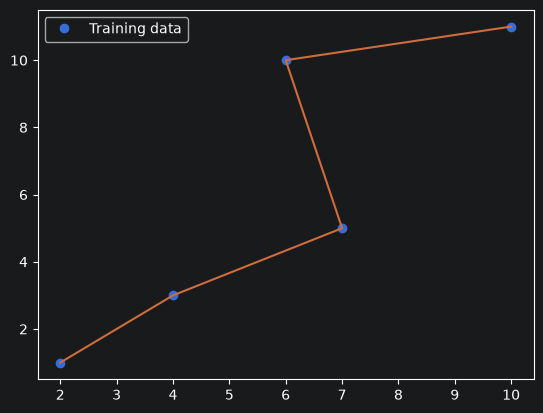

In [20]:
training = np.array([1,2,3,4,5,6,7,8,9,10]).reshape(-1,2).copy()
deviaion = random.randint(4,size=(training.shape))-2
training = training-deviaion
x_input = training[:,0]
y_output = training[:,1]
print(f"Training data: {training}")
plt.plot(x_input, y_output, 'o', label="Training data")
plt.plot(x_input, y_output)
plt.legend()
plt.show()

Cost function and testing it:

In [21]:
#Cost function:
def cost_function(y,y_hat):
    return np.average((y-y_hat)**2)/2

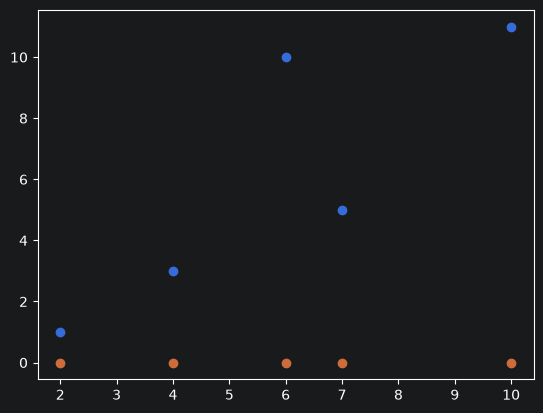

Cost function: 0.0


In [22]:
#Weight:
w = 0
#Bias:
b = 0
y_hat = x_input * w + b
plt.plot(x_input, y_output, 'o', label="Training data")
plt.plot(x_input, y_hat,'o',label="Trained data")
plt.show()
print(f"Cost function: {cost_function(y_output, y_output)}")

Brute force linear regression:

Cost value: 631.48 Values: -4.41,-0.46
Cost value: 193.19 Values: 4.24,-0.83
Cost value: 24.99 Values: 2.77,-4.79
Cost value: 8.98 Values: 2.27,-4.77
Cost value: 8.74 Values: 0.42,0.62
Cost value: 2.19 Values: 1.35,-2.10


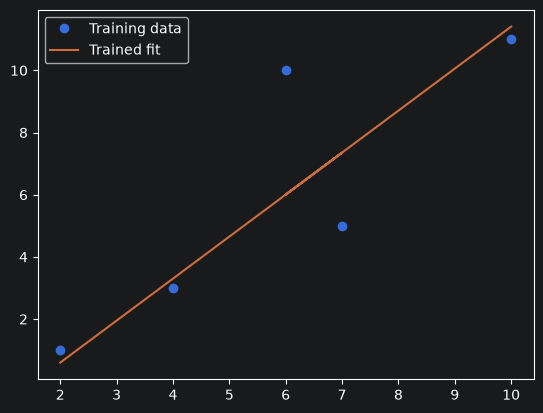

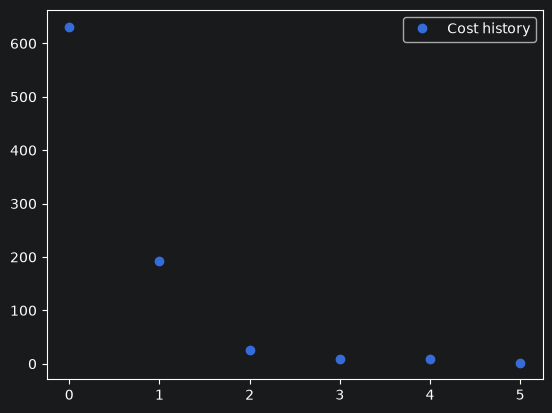

In [23]:
#Brute force linear regression:
cost = np.inf
w,b = 0,0
cost_history = []
for i in range(100):
    new_w,new_b = np.random.uniform(-5,5,size=(2))
    y_hat = x_input * new_w + new_b
    new_cost = cost_function(y_hat, y_output)
    if new_cost < cost:
        cost_history.append(new_cost)
        cost = new_cost
        w,b = new_w,new_b
        print(f"Cost value: {new_cost:.2f} Values: {w:.2f},{b:.2f}")

plt.plot(x_input, y_output, 'o', label="Training data")
plt.plot(x_input, x_input*w + b ,label="Trained fit")
plt.legend()
plt.show()

plt.plot(cost_history,'o', label="Cost history")
plt.legend()
plt.show()

In [24]:
#making it a function:
def brute_force_linear_regression(x_input, iterations=100):
    cost = np.inf
    w, b = 0, 0
    for i in range(iterations):
        new_w, new_b = np.random.uniform(-5, 5, size=(2))
        y_hat = x_input * new_w + new_b
        new_cost = cost_function(y_hat, y_output)
        if new_cost < cost:
            cost = new_cost
            w, b = new_w, new_b
    return w,b

Testing gradient descent

Numerical gradient descent

In [25]:
def calc_cost(w,b,x,y):
    return cost_function(x*w+b,y)

Cost value: 20.89 Values: 0.10,0.10
Cost value: 8.56 Values: 0.49,0.15
Cost value: 4.39 Values: 0.72,0.18
Cost value: 2.98 Values: 0.85,0.20
Cost value: 2.50 Values: 0.93,0.21
Cost value: 2.34 Values: 0.97,0.21
Cost value: 2.28 Values: 1.00,0.21
Cost value: 2.26 Values: 1.02,0.21


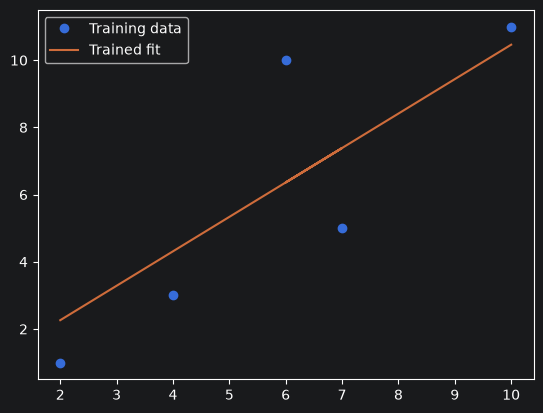

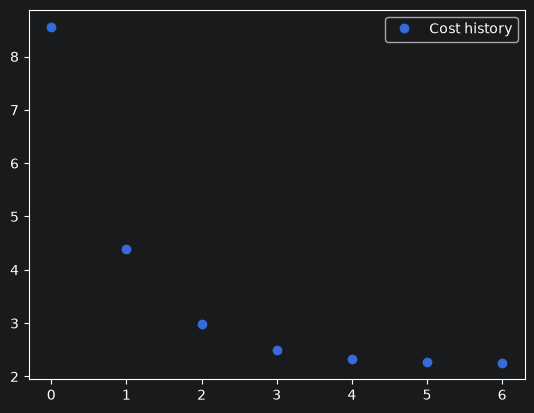

In [33]:
#w = 2-a*delta(J(w,b))/delta(w)
#b = 2-a*delta(J(w,b))/delta(b)

# w,b = np.random.uniform(-1,1,size=(2))
w,b = 0.1,0.1
cost = calc_cost(w,b,x_input,y_output)
print(f"Cost value: {cost:.2f} Values: {w:.2f},{b:.2f}")

cost_history = []
learning_rate = 0.01
delta = 0.0001

cut_off = 0.01

max_iterations = 10000

for _ in range(max_iterations):
    new_w = w - learning_rate * (calc_cost(w+delta,b,x_input,y_output)-cost)/delta
    new_b = b - learning_rate * (calc_cost(w,b+delta,x_input,y_output)-cost)/delta
    w,b = new_w,new_b

    y_hat = x_input*w + b
    new_cost = cost_function(y_hat, y_output)
    if (abs(new_cost-cost) < cut_off):
        break
    cost = new_cost
    cost_history.append(cost)
    print(f"Cost value: {cost:.2f} Values: {w:.2f},{b:.2f}")


plt.plot(x_input, y_output, 'o', label="Training data")
plt.plot(x_input, x_input*w + b ,label="Trained fit")
plt.legend()
plt.show()

plt.plot(cost_history,'o', label="Cost history")
plt.legend()
plt.show()

Analytical gradient descent

Cost value: 20.89 Values: 0.10,0.10
Cost value: 8.56 Values: 0.49,0.15
Cost value: 4.39 Values: 0.72,0.18
Cost value: 2.98 Values: 0.85,0.20
Cost value: 2.50 Values: 0.93,0.21
Cost value: 2.33 Values: 0.97,0.21
Cost value: 2.28 Values: 1.00,0.21
Cost value: 2.26 Values: 1.02,0.21


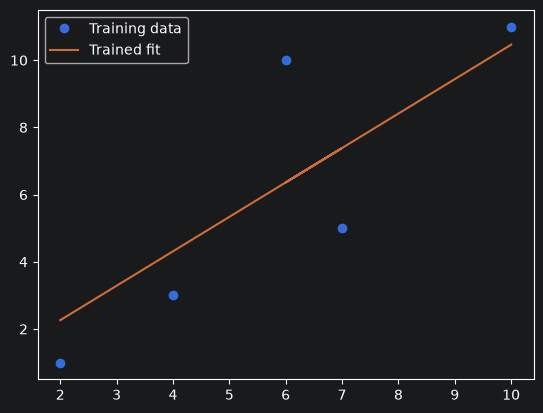

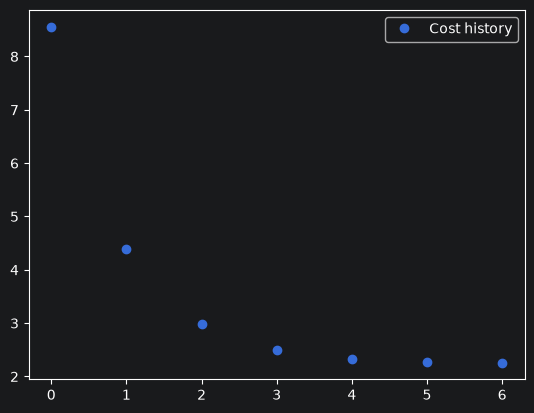

In [34]:
w,b = np.random.uniform(-1,1,size=(2))
w,b = 0.1,0.1
cost = calc_cost(w,b,x_input,y_output)
y_hat = x_input*w + b
print(f"Cost value: {cost:.2f} Values: {w:.2f},{b:.2f}")

cost_history = []
learning_rate = 0.01
delta = 0.0001

cut_off = 0.01

max_iterations = 10000

for _ in range(max_iterations):
    error = y_hat-y_output
    new_w = w - learning_rate*np.average(error*x_input)
    new_b = b - learning_rate*np.average(error)
    w,b = new_w,new_b

    y_hat = x_input*w + b
    new_cost = cost_function(y_hat, y_output)
    if (abs(new_cost-cost) < cut_off):
        break
    cost = new_cost
    cost_history.append(cost)
    print(f"Cost value: {cost:.2f} Values: {w:.2f},{b:.2f}")

plt.plot(x_input, y_output, 'o', label="Training data")
plt.plot(x_input, x_input*w + b ,label="Trained fit")
plt.legend()
plt.show()

plt.plot(cost_history,'o', label="Cost history")
plt.legend()
plt.show()